# Dimensions, Buckingham Pi and scaling

**Source:** CompSci §§2–2.3, pp. 7–14 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

Represent dimensions by exponents of mass, length and time. For $N$ quantities and a dimensional matrix $A$ of rank $r$, each independent null vector $v$ gives a dimensionless product $\prod_i q_i^{v_i}$; there are $N-r$ such groups. For a pendulum, $T\sqrt{g/L}$ is dimensionless and mass cancels. The prefactor can still depend on the dimensionless initial angle. The small-angle ODE gives $2\pi$.

For decay $u'=-au$ with $u(0)=I>0$, use $\tau=at$ and $U=u/I$. The chain rule gives $U'=-U$ and redimensionalisation gives $u=I e^{-at}$. For $m\ddot u+c\dot u+ku=F_0\sin(\omega t)$, choose $U=ku/F_0$, $\tau=\omega t$; then $(m\omega^2/k)U''+(c\omega/k)U'+U=\sin\tau$. The argument is $\tau$, since the frequency is already in the time scale.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


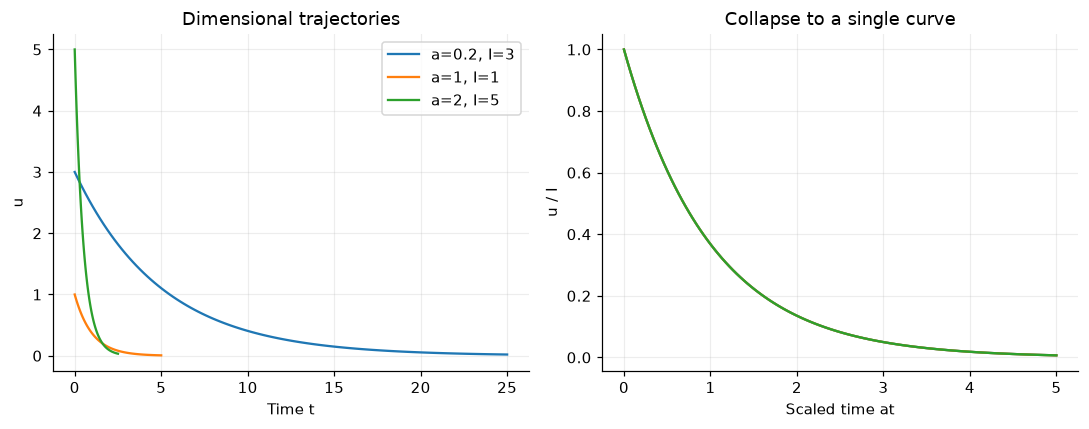

In [2]:
A=np.array([[0,0,0,1],[0,1,1,0],[1,0,-2,0]])
v=np.array([1,-.5,.5,0])
assert np.linalg.matrix_rank(A)==3 and np.allclose(A@v,0)
tau=np.linspace(0,5,120)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,I in [(.2,3),(1,1),(2,5)]:
    t=tau/a; u=I*np.exp(-a*t)
    ax[0].plot(t,u,label=f"a={a}, I={I}")
    ax[1].plot(a*t,u/I)
    assert np.allclose(u/I,np.exp(-tau))
ax[0].set(xlabel="Time t",ylabel="u",title="Dimensional trajectories"); ax[0].legend()
ax[1].set(xlabel="Scaled time at",ylabel="u / I",title="Collapse to a single curve")
show(fig,"02-scaling")

## Worked exercise

**What happens if time is scaled by the half-life?** Then $\tau=at/\log 2$, so $U'=-\log(2)U$ and $U(1)=1/2$. Dimensionless groups constrain form; they do not prove the model is physically complete.

## Further practice

Derive the oscillator groups using the dimension matrix for k, F0 and omega. Explain why choosing F0 as a scale fails when F0=0.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.